# 04 · Interpretación de resultados

**Proyecto:** Evolución de los ingresos laborales según edad, educación y región en Argentina (EPH, INDEC, 2.º trimestre 2017–2026)
**Etapa:** 6 – Interpretar y presentar · **Versión:** 23/11/2026

## Objetivo

Reunir en un solo lugar los hallazgos del proyecto, explicados en lenguaje claro, junto a las figuras que los muestran. Cada hallazgo va seguido de una celda de código que **recalcula las cifras citadas** a partir de las tablas de `resultados/`. Así, el texto se puede verificar y, si cambian los datos, se detecta qué cifra quedó desactualizada.

Este notebook **no genera archivos nuevos**: solo lee. El mismo texto está en `documentacion/hallazgos_y_limitaciones.md`, que es la versión de lectura.

## Entradas

| Tipo | Archivos (en `resultados/`) | Generados por |
|---|---|---|
| Tablas | 13 CSV: `p21_real_anual`, `ing_lab_real_anual`, `p21_real_anual_edad`, `p21_real_anual_educacion`, `p21_real_anual_region`, `robustez_variaciones`, `tasas_anual`, `resumen_etapas`, `resumen_etapas_edad`, `resumen_etapas_educacion`, `resumen_etapas_region`, `correlacion_educ_ingreso_anual`, `sensibilidad_deflactor` | `02_analisis.ipynb` |
| Figuras | 7 SVG: `fig01` a `fig07` | `03_visualizaciones.ipynb` |

**Orden de ejecución del proyecto:** `01_preparacion` → `02_analisis` → `03_visualizaciones` → `04_interpretacion`. Si la sesión se reinicia, hay que volver a ejecutar las secciones 1 a 4 antes de continuar.

## Criterios de interpretación

1. **Describir, no atribuir causas:** se escribe "durante la cuarentena", nunca "por la cuarentena".
2. **2020 y 2021 son contexto:** las conclusiones comparan antes (2017–2019) con después (2022–2026), ambos relevados en persona.
3. **Media y mediana juntas:** una variación es sólida (robusta) si ambas coinciden en dirección y difieren en menos de 4 puntos.
4. **2026 es una base preliminar**, y se señala.

## Índice

1. Configuración del entorno
2. Versiones
3. Carga de tablas y figuras
4. Funciones auxiliares
5. En pocas palabras
6. A quién representan los resultados
7. Cómo leer 2020 y 2021
8. Hallazgo 1: ingreso año por año
9. Hallazgo 2: edad
10. Hallazgo 3: nivel educativo
11. Hallazgo 4: región
12. Hallazgo 5: ingreso ampliado
13. Hallazgo 6: empleo y desempleo
14. Hallazgo 7: antes, durante y después
15. Limitaciones
16. Glosario
17. Control de cifras citadas

## 1. Configuración del entorno

Monta Google Drive y define las rutas del proyecto. Si el notebook se ejecuta fuera de Colab (por ejemplo, en una computadora con una copia de la carpeta `eph_ingresos`), usa como raíz la carpeta superior a `notebooks/`.

También importa las librerías: **pandas** para las tablas y `IPython.display` para mostrar las figuras SVG dentro del notebook.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import SVG, display

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ = Path('/content/drive/MyDrive/eph_ingresos')
else:
    RAIZ = Path.cwd().parent  # ejecución local: el notebook está en eph_ingresos/notebooks/

RESULTADOS = RAIZ / 'resultados'
DOCUMENTACION = RAIZ / 'documentacion'

print('Raíz del proyecto:', RAIZ)
print('¿Existe resultados/?', RESULTADOS.exists())

Mounted at /content/drive
Raíz del proyecto: /content/drive/MyDrive/eph_ingresos
¿Existe resultados/? True


## 2. Versiones

Versiones de referencia del proyecto (registradas el 11/11/2026): Python 3.13.18 y pandas 2.2.3. Si difieren y aparecen errores o resultados distintos, hay que compararlas con esta referencia.

In [2]:
import platform

print('Python:', platform.python_version())
print('pandas:', pd.__version__)

Python: 3.13.18
pandas: 2.2.3


## 3. Carga de tablas y figuras

Se cargan las 13 tablas en el diccionario `tablas` (la clave es el nombre del archivo sin `.csv`) y se comprueba que existan las 7 figuras. Si falta algún archivo, la celda lo informa y se detiene.

In [3]:
NOMBRES_TABLAS = [
    'p21_real_anual', 'ing_lab_real_anual',
    'p21_real_anual_edad', 'p21_real_anual_educacion', 'p21_real_anual_region',
    'robustez_variaciones', 'tasas_anual',
    'resumen_etapas', 'resumen_etapas_edad', 'resumen_etapas_educacion', 'resumen_etapas_region',
    'correlacion_educ_ingreso_anual', 'sensibilidad_deflactor',
]
FIGURAS = [
    'fig01_ingreso_anual', 'fig02_ingreso_ampliado', 'fig03_ingreso_edad',
    'fig04_ingreso_educacion', 'fig05_ingreso_region', 'fig06_empleo_desempleo',
    'fig07_resumen_etapas',
]

faltantes = [f'{n}.csv' for n in NOMBRES_TABLAS if not (RESULTADOS / f'{n}.csv').exists()]
faltantes += [f'{n}.svg' for n in FIGURAS if not (RESULTADOS / f'{n}.svg').exists()]
if faltantes:
    raise FileNotFoundError(f'Faltan archivos en resultados/: {faltantes}')

tablas = {n: pd.read_csv(RESULTADOS / f'{n}.csv') for n in NOMBRES_TABLAS}
print(f'{len(tablas)} tablas y {len(FIGURAS)} figuras disponibles.')

13 tablas y 7 figuras disponibles.


## 4. Funciones auxiliares

- `variacion(desde, hasta)`: variación porcentual entre dos valores.
- `pct(x)` y `millones(x)`: formatean números como en el texto (coma decimal).
- `mostrar(figura)`: muestra una figura SVG de `resultados/`.
- `miles(x)` y `dec(x)`: formatean enteros y decimales.
- `citar(clave, valor)`: guarda cada cifra citada en el diccionario `citadas`, que se controla en la sección 17.

In [4]:
def variacion(desde, hasta):
    """Variación porcentual de `desde` a `hasta`."""
    return (hasta / desde - 1) * 100


def pct(x, signo=True):
    """Formatea un porcentaje con una decimal y coma: −16,1 %."""
    texto = f'{x:+.1f}' if signo else f'{x:.1f}'
    return texto.replace('-', '−').replace('.', ',') + ' %'


def millones(x):
    """Formatea pesos en millones con dos decimales: 1,52."""
    return f'{x / 1e6:.2f}'.replace('.', ',')


def mostrar(figura):
    """Muestra una figura SVG de resultados/."""
    display(SVG(filename=str(RESULTADOS / f'{figura}.svg')))


citadas = {}  # clave -> valor recalculado (se controla en la sección 17)


def citar(clave, valor):
    """Guarda una cifra citada en el texto para controlarla en la sección 17."""
    citadas[clave] = valor


def miles(x):
    """Formatea enteros con punto de miles: 10.625."""
    return f'{x:,.0f}'.replace(',', '.')


def dec(x, n=2):
    """Formatea un número con coma decimal: 2,56."""
    return f'{x:.{n}f}'.replace('.', ',')

## 5. En pocas palabras

**Pregunta principal:** ¿cómo evolucionaron los ingresos laborales según la edad, el nivel educativo y la región entre 2017 y 2026?

- **El ingreso real de la ocupación principal es menor en 2026 que en 2017.** El promedio (media) bajó un 16,1 %, de 1,52 a 1,28 millones de pesos de octubre de 2026. El valor del medio (mediana) bajó un 13,9 %.
- **La caída no empezó en 2020.** Entre 2018 y 2019 la media y la mediana ya habían bajado alrededor de un 13 %. El punto más bajo de la serie es 2024, alrededor de un 30 % por debajo de 2017. En 2025 hubo un repunte y 2026 (dato preliminar) vuelve a quedar por debajo.
- **La caída alcanzó a todos los grupos**, pero el orden entre ellos se mantuvo:
  - las personas de 18 a 29 años siguen siendo las de menor ingreso;
  - a mayor nivel educativo, mayor ingreso;
  - Patagonia sigue siendo la región de ingresos más altos y el Noreste, una de las más bajas.
- **La magnitud de la caída varió.** Entre los grupos con resultados sólidos, el Noreste fue el que más cayó (−27,6 %). Varios grupos quedaron cerca del promedio general (−16,1 %), con caídas de entre el 16 % y el 17 %: entre ellos, las personas de 30 a 39 años, la región Pampeana y el nivel superior completo, que es el nivel educativo que menos cayó.
- **El mercado de trabajo y el ingreso se movieron en direcciones distintas.** Después de la cuarentena (2022–2026), en comparación con antes (2017–2019):
  - hay más personas ocupadas (61,3 % frente a 57,2 %);
  - hay menos desempleo (7,2 % frente a 9,6 %);
  - el ingreso real medio de quienes trabajan es alrededor de un 16 % menor.

Estos resultados **describen** lo que se observó. No permiten afirmar que la cuarentena, ni ningún otro factor, haya causado estos cambios.

Las cifras de esta síntesis se recalculan en las secciones 8 a 14.

## 6. A quién representan los resultados

- **Personas de 18 años o más que viven en los 31 aglomerados urbanos que releva la EPH.** No representan a la población rural ni al total del país.
- **Ingresos:** corresponden a las personas **ocupadas** que declararon un ingreso mayor a cero en su ocupación principal.
  - Las personas ocupadas que declararon ingreso cero, entre el 2,2 % y el 3,0 % por año (4,5 % en 2020), se informan aparte.
  - Quienes no declararon su ingreso se compensan con el ponderador que publica el INDEC para ese fin (PONDIIO). Ver la limitación 4.
- **Empleo y desempleo:** se calculan sobre toda la población de 18 años o más de esos aglomerados (empleo) o sobre quienes trabajan o buscan trabajo (desempleo).
- **Pesos constantes:** todos los ingresos están expresados en **pesos de octubre de 2026**, ajustados con el IPC nacional. Así, un valor de 2017 y uno de 2026 pueden compararse en poder de compra.
- **Período:** solo el segundo trimestre de cada año. No describe lo que pasó en el resto de cada año.
- **Tamaño de la muestra:** entre 10.625 (2020) y 20.985 (2019) personas ocupadas con ingreso informado por año.

In [5]:
p21 = tablas['p21_real_anual'].set_index('ANO4')
tasas = tablas['tasas_anual'].set_index('ANO4')

n_min, n_max = p21['n'].min(), p21['n'].max()
print(f"Ocupados con ingreso informado por año: entre {miles(n_min)} ({p21['n'].idxmin()}) y {miles(n_max)} ({p21['n'].idxmax()})")

cero = tasas['ingreso_cero']
sin_2020 = cero.drop(2020)
print(f'Ocupados con ingreso cero: entre {pct(sin_2020.min(), False)} y {pct(sin_2020.max(), False)}; en 2020, {pct(cero[2020], False)}')

citar('n_min', n_min); citar('n_max', n_max)
citar('cero_min', round(sin_2020.min(), 1)); citar('cero_max', round(sin_2020.max(), 1)); citar('cero_2020', round(cero[2020], 1))

Ocupados con ingreso informado por año: entre 10.625 (2020) y 20.985 (2019)
Ocupados con ingreso cero: entre 2,2 % y 3,0 %; en 2020, 4,5 %


## 7. Cómo leer 2020 y 2021

**Qué cambió en la encuesta**

La Encuesta Permanente de Hogares (EPH) suele hacerse en persona: un encuestador del INDEC visita las viviendas seleccionadas y entrevista a sus integrantes. Con las restricciones de la cuarentena, desde el segundo trimestre de 2020 hasta el primero de 2022 se hizo por teléfono. En este proyecto quedan afectados dos de los diez años analizados: 2020 y 2021.

**Qué consecuencias tuvo sobre los datos**

El cambio afectó tres aspectos.

- **Respondió menos gente.** En el segundo trimestre de 2020, de 26.940 viviendas seleccionadas respondieron 11.841, el 44 %. Cuando la respuesta baja tanto, crece el riesgo de que quienes contestan no se parezcan a quienes no lo hacen. Por ejemplo, puede que sea más fácil contactar a algunos hogares que a otros. El INDEC ajustó los ponderadores para compensarlo, pero el ajuste no elimina el problema por completo.
- **La calidad no fue pareja entre regiones.** Quince aglomerados no alcanzaron el estándar de calidad del INDEC en 2020. Entre ellos están la Ciudad de Buenos Aires y los partidos del Gran Buenos Aires, los dos aglomerados que forman la región GBA, la más poblada. En este proyecto, GBA pasa de unos 3.200 ocupados con ingreso informado por año en 2017–2019 a 994 en 2020 y 1.169 en 2021. Sus cifras de esos años son las menos precisas de toda la serie.
- **Los ingresos se declararon con menos exactitud.** Hay evidencia de que, durante el período telefónico, la distancia entre los ingresos declarados en la encuesta y los ingresos reales se amplió. Como el indicador central de este proyecto es justamente un ingreso, los valores de 2020 y 2021 podrían estar más subestimados que los de otros años.

**Qué significa para la interpretación**

Las cifras de 2020 y 2021 combinan dos cosas que no se pueden separar: lo que efectivamente ocurrió en el mercado de trabajo durante la cuarentena y el efecto de haber cambiado la forma de relevar los datos. Por ejemplo, la tasa de empleo baja del 57,4 % en 2019 al 46,9 % en 2020, y la de desempleo sube del 10,6 % al 13,1 %. La dirección de esos cambios es clara, pero su tamaño exacto debe leerse con cautela.

**Cómo se usan en este proyecto**

- **Se muestran.** Forman parte de la serie y dan contexto. En los gráficos aparecen señalados con una franja gris, y en el resumen por etapas, con una barra rayada.
- **No sostienen las conclusiones.** Los hallazgos principales comparan los años en que la encuesta se hizo en persona: antes (2017–2019) y después (2022–2026). Esa comparación es más confiable porque ambos períodos se relevaron de la misma manera.
- **No miden el impacto de la cuarentena.** Este proyecto describe lo que se observó durante esos años; no afirma que la cuarentena haya causado esos cambios ni estima cuánto los causó.

In [6]:
reg = tablas['p21_real_anual_region']
gba = reg[reg['region'] == 'Gran Buenos Aires'].set_index('ANO4')['n']
print(f"GBA, ocupados con ingreso informado: promedio 2017–2019 = {miles(gba.loc[2017:2019].mean())}; 2020 = {miles(gba[2020])}; 2021 = {miles(gba[2021])}")

print(f"Empleo: 2019 = {pct(tasas.loc[2019, 'tasa_empleo'], False)} → 2020 = {pct(tasas.loc[2020, 'tasa_empleo'], False)}")
print(f"Desempleo: 2019 = {pct(tasas.loc[2019, 'tasa_desempleo'], False)} → 2020 = {pct(tasas.loc[2020, 'tasa_desempleo'], False)}")

citar('gba_2020', gba[2020]); citar('gba_2021', gba[2021])
citar('empleo_2019', round(tasas.loc[2019, 'tasa_empleo'], 1)); citar('empleo_2020', round(tasas.loc[2020, 'tasa_empleo'], 1))
citar('desempleo_2019', round(tasas.loc[2019, 'tasa_desempleo'], 1)); citar('desempleo_2020', round(tasas.loc[2020, 'tasa_desempleo'], 1))

GBA, ocupados con ingreso informado: promedio 2017–2019 = 3.270; 2020 = 994; 2021 = 1.169
Empleo: 2019 = 57,4 % → 2020 = 46,9 %
Desempleo: 2019 = 10,6 % → 2020 = 13,1 %


## Hallazgos por pregunta (secciones 8 a 14)

Cada hallazgo indica **qué se observa**, **con qué grado de certeza** y **qué figura lo muestra**. Las variaciones comparan 2017 con 2026, salvo que se indique otra cosa. Debajo de cada texto, una celda muestra la figura y recalcula las cifras citadas.

## 8. Hallazgo 1: ingreso año por año

**Pregunta:** ¿Cómo cambió el ingreso de la ocupación principal año por año?

### Qué se observa

| Año | Media (millones) | Mediana (millones) |
|---|---|---|
| 2017 | 1,52 | 1,18 |
| 2018 | 1,52 | 1,31 |
| 2019 | 1,32 | 1,14 |
| 2020 ▒ | 1,32 | 1,11 |
| 2021 ▒ | 1,27 | 1,00 |
| 2022 | 1,19 | 0,98 |
| 2023 | 1,21 | 1,02 |
| 2024 | 1,06 | 0,82 |
| 2025 | 1,38 | 1,05 |
| 2026 (prel.) | 1,28 | 1,01 |

▒ Relevamiento telefónico. Pesos de octubre de 2026.

- Entre 2018 y 2019, antes de la cuarentena, la media y la mediana bajan alrededor de un 13 %.
- En 2020 y 2021 (relevamiento telefónico) la serie sigue bajando, de forma moderada.
- **2024 es el punto más bajo:** la media queda un 30,5 % por debajo de 2017 y la mediana, un 30,2 %.
- En 2025 hay un repunte: alrededor de un +30 % respecto de 2024.
- En 2026 (dato preliminar), la media baja un 7,3 % respecto de 2025.
- **Saldo 2017–2026:** −16,1 % con la media y −13,9 % con la mediana.

### Con qué grado de certeza

- La caída entre 2017 y 2026 es sólida: se repite con la media y la mediana, y con cuatro formas distintas de ajustar por inflación (entre −15,9 % y −16,5 %).
- 2024 es el mínimo con cualquiera de esas cuatro formas.
- **El tamaño del repunte de 2025 es incierto:** según el mes de precios que se tome como referencia, va de +24 % a +35 %. Se debe a la inflación mensual muy alta de comienzos de 2024 (limitación 7).
- 2026 es una base preliminar.

**Figura:** `fig01_ingreso_anual` (media, mediana y banda de sensibilidad al ajuste por inflación).

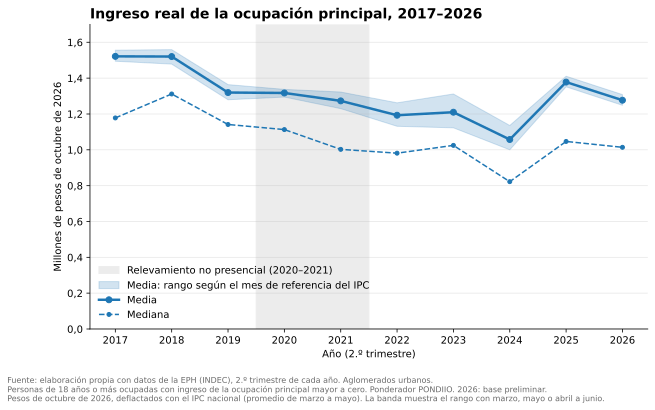

,media (millones),mediana (millones)
ANO4,,
2017,"1,52","1,18"
2018,"1,52","1,31"
2019,"1,32","1,14"
2020,"1,32","1,11"
2021,"1,27","1,00"
2022,"1,19","0,98"
2023,"1,21","1,02"
2024,"1,06","0,82"
2025,"1,38","1,05"


media    2018→2019: −13,2 % | 2017→2024: −30,5 % | 2025→2026: −7,3 % | 2017→2026: −16,1 %
mediana  2018→2019: −13,0 % | 2017→2024: −30,2 % | 2025→2026: −3,1 % | 2017→2026: −13,9 %

Sensibilidad (4 escenarios del deflactor):
  2017→2026: entre −16,5 % y −15,9 %
  2024→2025: entre +24,2 % y +35,2 %
  ¿2024 es el mínimo en todos los escenarios? True


In [7]:
mostrar('fig01_ingreso_anual')

tabla = pd.DataFrame({
    'media (millones)': p21['media'].map(millones),
    'mediana (millones)': p21['mediana'].map(millones),
})
display(tabla)

for col in ['media', 'mediana']:
    s = p21[col]
    print(f'{col:8} 2018→2019: {pct(variacion(s[2018], s[2019]))} | 2017→2024: {pct(variacion(s[2017], s[2024]))} | '
          f'2025→2026: {pct(variacion(s[2025], s[2026]))} | 2017→2026: {pct(variacion(s[2017], s[2026]))}')

sens = tablas['sensibilidad_deflactor'].set_index('ANO4')
var_17_26 = variacion(sens.loc[2017], sens.loc[2026])
rep_25 = variacion(sens.loc[2024], sens.loc[2025])
print(f'\nSensibilidad (4 escenarios del deflactor):')
print(f'  2017→2026: entre {pct(var_17_26.min())} y {pct(var_17_26.max())}')
print(f'  2024→2025: entre {pct(rep_25.min())} y {pct(rep_25.max())}')
print(f'  ¿2024 es el mínimo en todos los escenarios? {(sens.idxmin() == 2024).all()}')

citar('media_17_26', round(variacion(p21.loc[2017, 'media'], p21.loc[2026, 'media']), 1))
citar('mediana_17_26', round(variacion(p21.loc[2017, 'mediana'], p21.loc[2026, 'mediana']), 1))
citar('media_17_24', round(variacion(p21.loc[2017, 'media'], p21.loc[2024, 'media']), 1))
citar('mediana_17_24', round(variacion(p21.loc[2017, 'mediana'], p21.loc[2024, 'mediana']), 1))
citar('media_25_26', round(variacion(p21.loc[2025, 'media'], p21.loc[2026, 'media']), 1))
citar('sens_min', round(var_17_26.min(), 1)); citar('sens_max', round(var_17_26.max(), 1))
citar('rep_min', round(rep_25.min())); citar('rep_max', round(rep_25.max()))

## 9. Hallazgo 2: edad

**Pregunta:** ¿Qué diferencias se observan entre los grupos de edad?

### Qué se observa

- **Los tres grupos de 18 a 64 años caen en magnitudes parecidas:** 18 a 29 años, −18,4 %; 30 a 39 años, −16,6 %; 40 a 64 años, −17,8 % (con la media).
- **Las personas de 18 a 29 años tienen siempre el ingreso más bajo.** En 2026, su media (0,93 millones) equivale a dos tercios de la del grupo de 40 a 64 años (1,40 millones). Esa proporción es la misma que en 2017.
- El grupo de 40 a 64 años tiene la media más alta entre los grupos de 18 a 64, entre un 4,1 % y un 14,9 % por encima del de 30 a 39, según el año. Con la mediana, los dos grupos empatan en casi todos los años (ver limitación 6).
- En los cuatro grupos, 2024 es el año más bajo.

### Con qué grado de certeza

- Las variaciones de los tres grupos de 18 a 64 años son sólidas.
- **El grupo de 65 años o más no es concluyente.** Con la media cae un 6,2 % y con la mediana, un 28,3 %. Es el grupo más chico (entre 308 y 776 casos por año) y sus valores oscilan mucho de un año a otro.
- El grupo de 65 años o más se define solo por la edad. No se asume que sus integrantes estén jubilados: son personas de esa edad que trabajan.

**Figura:** `fig03_ingreso_edad` (un panel por grupo; 65 o más en gris).

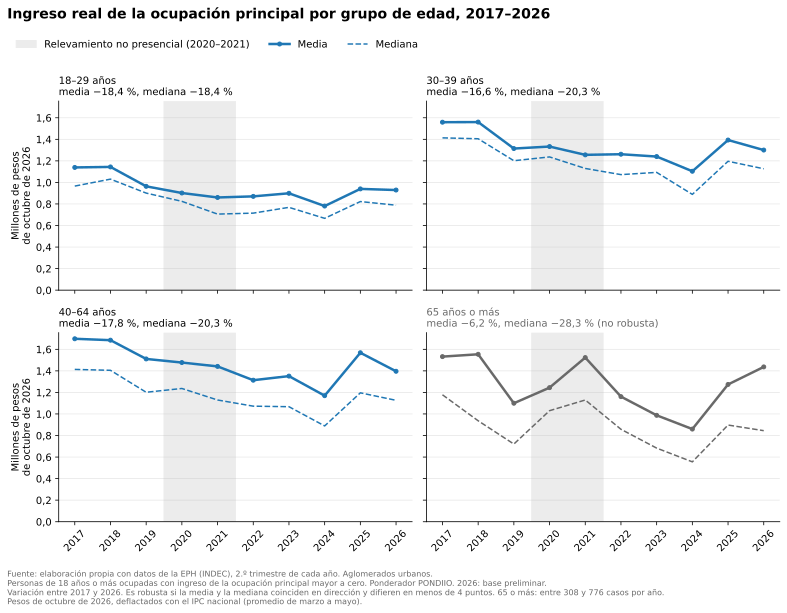

,corte,grupo,var_media_%,var_mediana_%,diferencia_puntos,robusta
1,edad,18-29,-18.4,-18.4,0.1,True
2,edad,30-39,-16.6,-20.3,3.7,True
3,edad,40-64,-17.8,-20.3,2.5,True
4,edad,65 o más,-6.2,-28.3,22.0,False


2017: media 18–29 / media 40–64 = 0,67
2026: media 18–29 / media 40–64 = 0,67
40–64 sobre 30–39: entre +4,1 % y +14,9 %
Año mínimo por grupo: {'18-29': 2024, '30-39': 2024, '40-64': 2024, '65 o más': 2024}
Casos de 65 o más por año: entre 308 y 776


In [8]:
mostrar('fig03_ingreso_edad')

rob = tablas['robustez_variaciones']
display(rob[rob['corte'] == 'edad'].round(1))

edad = tablas['p21_real_anual_edad'].pivot(index='ANO4', columns='grupo_edad', values='media')
for anio in (2017, 2026):
    print(f"{anio}: media 18–29 / media 40–64 = {dec(edad.loc[anio, '18-29'] / edad.loc[anio, '40-64'])}")
dif = variacion(edad['30-39'], edad['40-64'])
print(f'40–64 sobre 30–39: entre {pct(dif.min())} y {pct(dif.max())}')
print('Año mínimo por grupo:', edad.idxmin().to_dict())
n65 = tablas['p21_real_anual_edad'].query("grupo_edad == '65 o más'")['n']
print(f'Casos de 65 o más por año: entre {n65.min()} y {n65.max()}')

r = rob.set_index(['corte', 'grupo'])
for g in ['18-29', '30-39', '40-64', '65 o más']:
    citar(f'edad_{g}', round(r.loc[('edad', g), 'var_media_%'], 1))
citar('edad_65_mediana', round(r.loc[('edad', '65 o más'), 'var_mediana_%'], 1))
citar('dif_40_30_min', round(dif.min(), 1)); citar('dif_40_30_max', round(dif.max(), 1))
citar('n65_min', n65.min()); citar('n65_max', n65.max())

## 10. Hallazgo 3: nivel educativo

**Pregunta:** ¿Cómo varían los ingresos según el nivel educativo?

### Qué se observa

- **A mayor nivel educativo, mayor ingreso, en todos los años.** La única excepción es menor: en 2023, el secundario incompleto queda apenas por debajo del primario completo.
- **El nivel superior completo es el que menos cae:** −17,0 % con la media y −17,1 % con la mediana.
- El secundario incompleto (−26,5 %) y el secundario completo (−20,2 %) caen más.
- **La distancia entre los extremos se amplía.** En 2017, una persona con nivel superior completo ganaba en promedio 2,56 veces lo que una con primario incompleto; en 2026, 2,83 veces.
- **Asociación entre educación e ingreso:** la correlación de Spearman es positiva y moderada todos los años. Va de 0,34 (2017) a 0,40 (2021) y vuelve a 0,33 (2026). El máximo cae en los años de relevamiento telefónico, así que ese aumento debe leerse con cautela. La correlación mide qué tan ordenada es la relación (más educación, más ingreso); no mide cuánto más se gana ni implica que la educación cause el ingreso.

### Con qué grado de certeza

- Son sólidas las variaciones de secundario incompleto, secundario completo y superior completo.
- **No son sólidas** las de primario incompleto (−24,9 % con la media; −36,2 % con la mediana), primario completo y superior incompleto: la media y la mediana difieren en más de 8 puntos.
- El primario incompleto es el grupo más chico, con entre 310 y 839 casos por año. Incluye a las personas sin instrucción.
- El nivel superior agrupa terciario, universitario y posgrado (limitación 11).

**Figura:** `fig04_ingreso_educacion` (un panel por nivel).

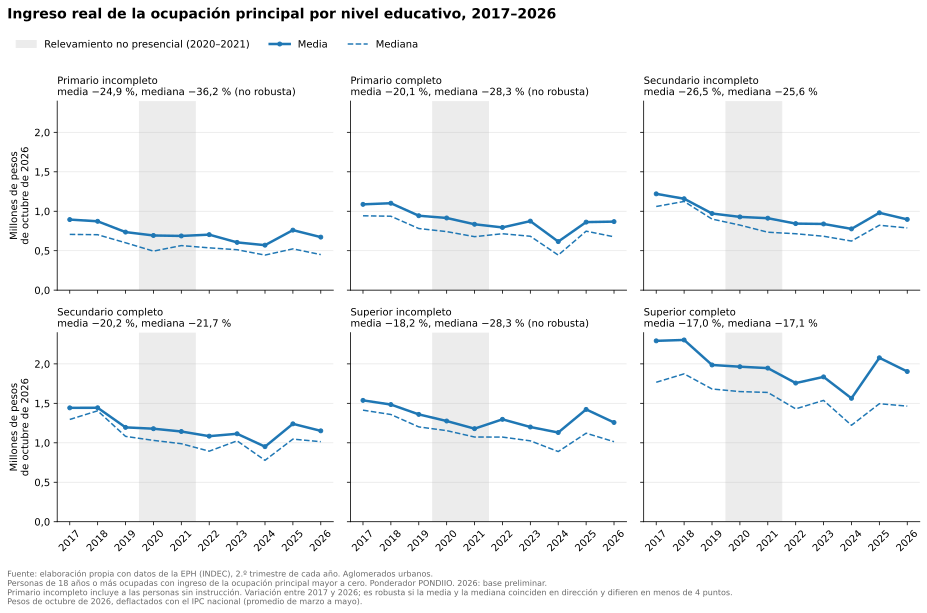

,corte,grupo,var_media_%,var_mediana_%,diferencia_puntos,robusta
5,educacion,Primario incompleto,-24.9,-36.2,11.4,False
6,educacion,Primario completo,-20.1,-28.3,8.1,False
7,educacion,Secundario incompleto,-26.5,-25.6,0.9,True
8,educacion,Secundario completo,-20.2,-21.7,1.6,True
9,educacion,Superior incompleto,-18.2,-28.3,10.1,False
10,educacion,Superior completo,-17.0,-17.1,0.2,True


Años en que el gradiente NO se cumple: [2023]
Brecha superior completo / primario incompleto: 2,56 (2017) → 2,83 (2026)
Spearman: 0,34 (2017), máximo 0,40 (2021), 0,33 (2026)
Casos de primario incompleto por año: entre 310 y 839


In [9]:
mostrar('fig04_ingreso_educacion')

display(rob[rob['corte'] == 'educacion'].round(1))

ORDEN_EDUC = ['Primario incompleto', 'Primario completo', 'Secundario incompleto',
              'Secundario completo', 'Superior incompleto', 'Superior completo']
educ = tablas['p21_real_anual_educacion'].pivot(index='ANO4', columns='nivel_educativo', values='media')[ORDEN_EDUC]
gradiente = (educ.diff(axis=1).iloc[:, 1:] > 0).all(axis=1)
print('Años en que el gradiente NO se cumple:', list(gradiente[~gradiente].index))

brecha = educ['Superior completo'] / educ['Primario incompleto']
print(f'Brecha superior completo / primario incompleto: {dec(brecha[2017])} (2017) → {dec(brecha[2026])} (2026)')

corr = tablas['correlacion_educ_ingreso_anual'].set_index('ANO4')['spearman_educ_p21']
print(f'Spearman: {dec(corr[2017])} (2017), máximo {dec(corr.max())} ({corr.idxmax()}), {dec(corr[2026])} (2026)')

n_pi = tablas['p21_real_anual_educacion'].query("nivel_educativo == 'Primario incompleto'")['n']
print(f'Casos de primario incompleto por año: entre {n_pi.min()} y {n_pi.max()}')

for g in ['Secundario incompleto', 'Secundario completo', 'Superior completo', 'Primario incompleto']:
    citar(f'educ_{g}', round(r.loc[('educacion', g), 'var_media_%'], 1))
citar('educ_sup_mediana', round(r.loc[('educacion', 'Superior completo'), 'var_mediana_%'], 1))
citar('educ_pi_mediana', round(r.loc[('educacion', 'Primario incompleto'), 'var_mediana_%'], 1))
citar('brecha_2017', round(brecha[2017], 2)); citar('brecha_2026', round(brecha[2026], 2))
citar('spearman_2017', round(corr[2017], 2)); citar('spearman_max', round(corr.max(), 2)); citar('spearman_2026', round(corr[2026], 2))

## 11. Hallazgo 4: región

**Pregunta:** ¿Qué diferencias aparecen entre las regiones?

### Qué se observa

- **En 2026, las seis regiones están por debajo de 2017**, y en todas 2024 es el año más bajo.
- **El Noreste es la región que más cae:** −27,6 % con la media y −25,6 % con la mediana. En 2026 su ingreso equivale al 72 % del de 2017.
- Le sigue Cuyo (−22,2 %). Noroeste (−16,8 %) y Pampeana (−16,5 %) caen en una magnitud similar al promedio.
- **Patagonia tiene el ingreso más alto en todos los años.** Su media es alrededor de 1,8 veces la del Noroeste, tanto en 2017 como en 2026.

### Con qué grado de certeza

- Son sólidas las variaciones de Noreste, Cuyo, Noroeste y Pampeana.
- **No son sólidas las de Gran Buenos Aires y Patagonia.** Con la media caen un 14,1 % y un 18,1 %; con la mediana, un 20,3 % y un 28,3 %. No se puede afirmar que GBA sea la región que menos cae.
- Las cifras de GBA en 2020 y 2021 son las menos precisas de la serie (sección 7).
- **Los niveles entre regiones no son comparables en poder de compra.** Se usó el mismo índice de precios para todas, y el costo de vida no es igual (por ejemplo, en Patagonia). Por eso la figura compara la evolución de cada región (índice 2017 = 100) y no sus niveles. Las tendencias sí son comparables: con los índices de precios regionales cambian como máximo 0,8 puntos (limitación 10).

**Figura:** `fig05_ingreso_region` (índice 2017 = 100, un panel por región).

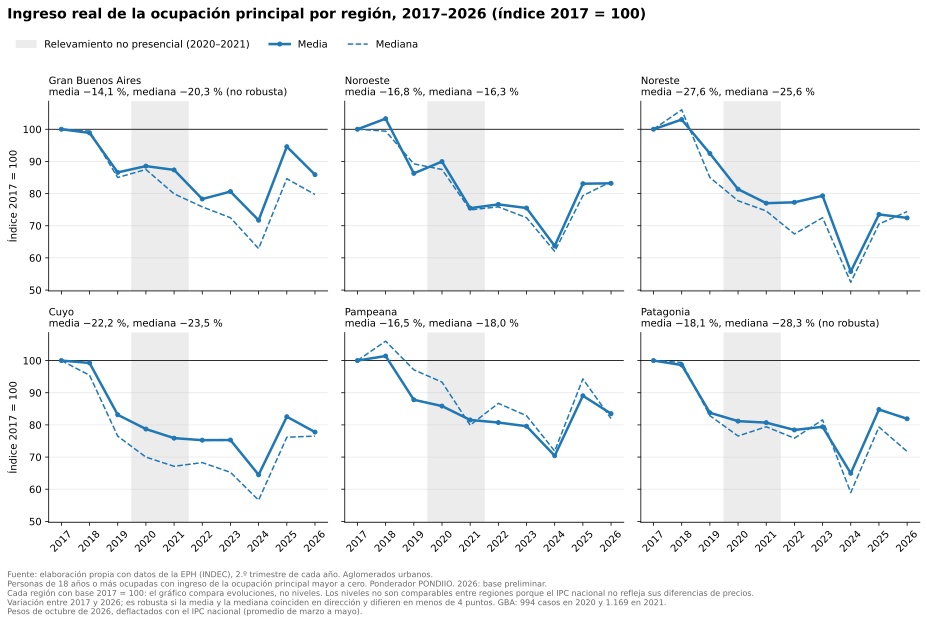

,corte,grupo,var_media_%,var_mediana_%,diferencia_puntos,robusta
11,region,Gran Buenos Aires,-14.1,-20.3,6.2,False
12,region,Noroeste,-16.8,-16.3,0.5,True
13,region,Noreste,-27.6,-25.6,2.0,True
14,region,Cuyo,-22.2,-23.5,1.3,True
15,region,Pampeana,-16.5,-18.0,1.5,True
16,region,Patagonia,-18.1,-28.3,10.2,False


Índice 2026 (2017 = 100): {'Cuyo': 77.8, 'Gran Buenos Aires': 85.9, 'Noreste': 72.4, 'Noroeste': 83.2, 'Pampeana': 83.5, 'Patagonia': 81.9}
Año mínimo por región: {'Cuyo': 2024, 'Gran Buenos Aires': 2024, 'Noreste': 2024, 'Noroeste': 2024, 'Pampeana': 2024, 'Patagonia': 2024}
Región con el ingreso más alto, por año: ['Patagonia']
Patagonia / Noroeste: 1,85 (2017) → 1,82 (2026)


In [10]:
mostrar('fig05_ingreso_region')

display(rob[rob['corte'] == 'region'].round(1))

region = tablas['p21_real_anual_region'].pivot(index='ANO4', columns='region', values='media')
indice_2026 = (region.loc[2026] / region.loc[2017] * 100).round(1)
print('Índice 2026 (2017 = 100):', indice_2026.to_dict())
print('Año mínimo por región:', region.idxmin().to_dict())
print('Región con el ingreso más alto, por año:', list(region.idxmax(axis=1).unique()))
pat_noa = region['Patagonia'] / region['Noroeste']
print(f'Patagonia / Noroeste: {dec(pat_noa[2017])} (2017) → {dec(pat_noa[2026])} (2026)')

for g in ['Noreste', 'Cuyo', 'Noroeste', 'Pampeana', 'Gran Buenos Aires', 'Patagonia']:
    citar(f'region_{g}', round(r.loc[('region', g), 'var_media_%'], 1))
citar('nea_mediana', round(r.loc[('region', 'Noreste'), 'var_mediana_%'], 1))
citar('indice_nea', round(indice_2026['Noreste']))

## 12. Hallazgo 5: ingreso ampliado

**Pregunta:** ¿Qué cambia al considerar también los ingresos de otras ocupaciones?

### Qué se observa

- Sumar los ingresos de otras ocupaciones eleva el ingreso medio entre un 3,8 % (2020) y un 5,9 % (2025).
- **Las dos series se mueven juntas:** mismos años de caída, mismo mínimo en 2024 y mismo repunte en 2025. Entre antes y después de la cuarentena, el ingreso ampliado baja un 15,3 %, frente a un 15,9 % del ingreso de la ocupación principal.
- Conclusión: tener más de un trabajo no cambia la tendencia general.

### Con qué grado de certeza

- El ingreso de otras ocupaciones puede incluir pagos atrasados o retroactivos que no se pueden separar (limitación 9). Por eso esta medida es un complemento y no reemplaza al indicador central.

**Figura:** `fig02_ingreso_ampliado`.

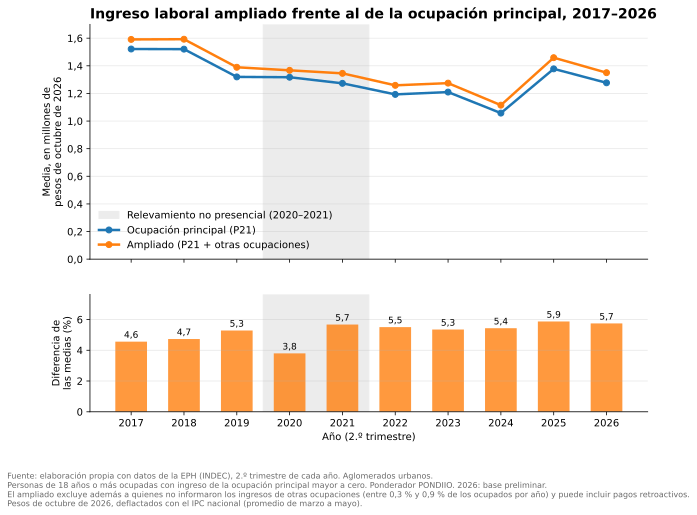

El ampliado supera al central entre +3,8 % (2020) y +5,9 % (2025)
Antes → después: ampliado −15,3 %, central −15,9 %


In [11]:
mostrar('fig02_ingreso_ampliado')

amp = tablas['ing_lab_real_anual'].set_index('ANO4')
dif_amp = variacion(p21['media'], amp['media'])
print(f'El ampliado supera al central entre {pct(dif_amp.min())} ({dif_amp.idxmin()}) y {pct(dif_amp.max())} ({dif_amp.idxmax()})')

et = tablas['resumen_etapas'].set_index('etapa')
print(f"Antes → después: ampliado {pct(variacion(et.loc['antes', 'amp_media'], et.loc['después', 'amp_media']))}, "
      f"central {pct(variacion(et.loc['antes', 'p21_media'], et.loc['después', 'p21_media']))}")

citar('amp_min', round(dif_amp.min(), 1)); citar('amp_max', round(dif_amp.max(), 1))
citar('amp_etapas', round(variacion(et.loc['antes', 'amp_media'], et.loc['después', 'amp_media']), 1))

## 13. Hallazgo 6: empleo y desempleo

**Pregunta:** ¿Cómo evolucionaron el empleo y el desempleo?

### Qué se observa

- **Antes de la cuarentena (2017–2019):** la tasa de empleo está entre el 56,9 % y el 57,4 %, y el desempleo sube del 8,7 % al 10,6 %.
- **2020 (relevamiento telefónico):** el empleo baja al 46,9 % y el desempleo sube al 13,1 %. La proporción de ocupados con ingreso cero sube al 4,5 %, frente a alrededor del 2,5 % en el resto de los años.
- **2021 (relevamiento telefónico):** el empleo vuelve al 57,7 % y el desempleo, al 9,6 %.
- **Desde 2022:** el empleo se mantiene alrededor del 61 %, por encima de los niveles anteriores a la cuarentena. El desempleo está entre el 6,2 % y el 7,9 %, por debajo.

### Con qué grado de certeza

- Las tasas de desempleo calculadas coinciden con las oficiales del INDEC para la población de 18 años o más, con una diferencia máxima de 0,1 puntos.
- La magnitud de los cambios de 2020 y 2021 debe leerse con cautela (sección 7).
- Las tasas miden cuántas personas trabajan o buscan trabajo, no la calidad del empleo. Este proyecto no analiza la informalidad, las horas trabajadas ni el tipo de ocupación.

**Figura:** `fig06_empleo_desempleo` (dos paneles, porque las tasas tienen bases distintas).

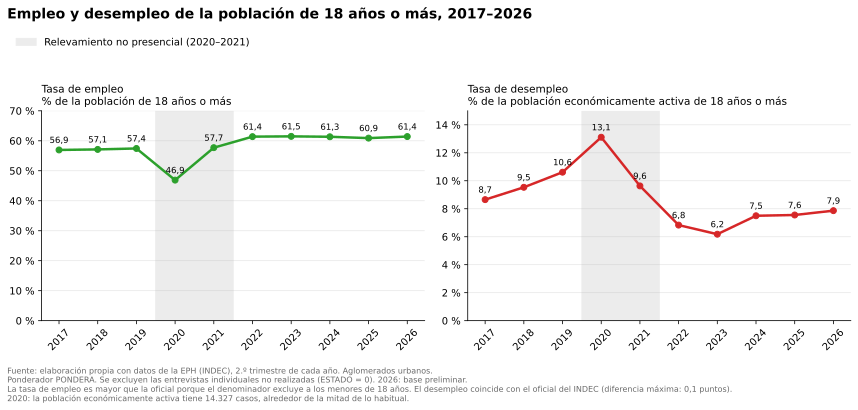

,tasa_empleo,tasa_desempleo,ingreso_cero
ANO4,,,
2017,56.9,8.7,2.6
2018,57.1,9.5,3.0
2019,57.4,10.6,2.9
2020,46.9,13.1,4.5
2021,57.7,9.6,2.4
2022,61.4,6.8,2.5
2023,61.5,6.2,2.3
2024,61.3,7.5,2.2
2025,60.9,7.6,2.8


Desde 2022: empleo entre 60,9 % y 61,5 %; desempleo entre 6,2 % y 7,9 %


In [12]:
mostrar('fig06_empleo_desempleo')

display(tasas[['tasa_empleo', 'tasa_desempleo', 'ingreso_cero']].round(1))

desde_2022 = tasas.loc[2022:]
print(f"Desde 2022: empleo entre {pct(desde_2022['tasa_empleo'].min(), False)} y {pct(desde_2022['tasa_empleo'].max(), False)}; "
      f"desempleo entre {pct(desde_2022['tasa_desempleo'].min(), False)} y {pct(desde_2022['tasa_desempleo'].max(), False)}")

citar('empleo_2021', round(tasas.loc[2021, 'tasa_empleo'], 1)); citar('desempleo_2021', round(tasas.loc[2021, 'tasa_desempleo'], 1))
citar('desempleo_2017', round(tasas.loc[2017, 'tasa_desempleo'], 1))
citar('desempleo_22_min', round(desde_2022['tasa_desempleo'].min(), 1)); citar('desempleo_22_max', round(desde_2022['tasa_desempleo'].max(), 1))

## 14. Hallazgo 7: antes, durante y después

**Pregunta:** ¿Qué se observa al resumir antes, durante y después de la cuarentena?

### Qué se observa

| Indicador | Antes (2017–2019) | Durante (2020–2021) ▒ | Después (2022–2026) |
|---|---|---|---|
| Ingreso real medio | 1,45 millones | 1,30 millones | 1,22 millones |
| Ingreso real mediano | 1,21 millones | 1,06 millones | 0,98 millones |
| Tasa de empleo | 57,2 % | 52,3 % | 61,3 % |
| Tasa de desempleo | 9,6 % | 11,4 % | 7,2 % |
| Ocupados con ingreso cero | 2,9 % | 3,4 % | 2,4 % |

▒ Relevamiento telefónico. Cada etapa es el promedio simple de sus años.

- **Hallazgo central:** después de la cuarentena hay **más empleo y menos desempleo** que antes, pero el **ingreso real de quienes trabajan es menor**: un 15,9 % con la media y un 19,2 % con la mediana.
- En otras palabras, en 2022–2026 más personas tienen trabajo, pero ese trabajo, en promedio, compra menos que en 2017–2019.
- El ingreso no se recuperó en "después": siguió por debajo de "durante".

### Con qué grado de certeza

- La comparación entre antes y después es la más confiable, porque ambas etapas se relevaron en persona.
- **"Después" promedia años muy distintos:** incluye el mínimo de 2024, el repunte de 2025 y el dato preliminar de 2026. El promedio no describe a ningún año en particular.
- La muestra es más chica en "después" que en "antes" (limitación 5).

**Figura:** `fig07_resumen_etapas` (barras por etapa; "durante" rayado).

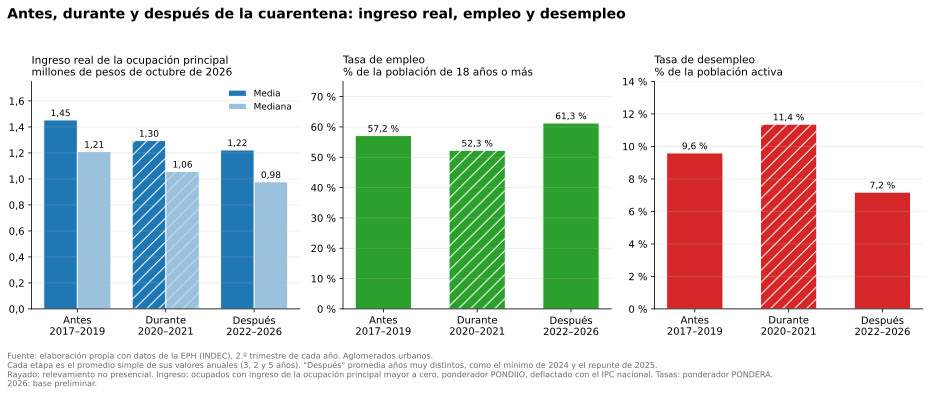

etapa,antes,durante,después
p21_media,1453886.50,1295167.77,1222974.26
p21_mediana,1210246.11,1057730.98,977749.00
tasa_empleo,57.17,52.29,61.30
tasa_desempleo,9.60,11.37,7.18
ingreso_cero,2.86,3.42,2.39


p21_media: después frente a antes −15,9 %
p21_mediana: después frente a antes −19,2 %


In [13]:
mostrar('fig07_resumen_etapas')

display(et[['p21_media', 'p21_mediana', 'tasa_empleo', 'tasa_desempleo', 'ingreso_cero']].T.round(2))

for col in ['p21_media', 'p21_mediana']:
    print(f"{col}: después frente a antes {pct(variacion(et.loc['antes', col], et.loc['después', col]))}")

citar('etapa_media', round(variacion(et.loc['antes', 'p21_media'], et.loc['después', 'p21_media']), 1))
citar('etapa_mediana', round(variacion(et.loc['antes', 'p21_mediana'], et.loc['después', 'p21_mediana']), 1))
for etapa in ['antes', 'durante', 'después']:
    citar(f'empleo_{etapa}', round(et.loc[etapa, 'tasa_empleo'], 1))
    citar(f'desempleo_{etapa}', round(et.loc[etapa, 'tasa_desempleo'], 1))

## 15. Limitaciones

Estas limitaciones no invalidan los resultados, pero indican hasta dónde se puede llegar con ellos. El detalle técnico está en la tarjeta "Comprobaciones y limitaciones" del tablero del proyecto.

**1. Cobertura.** La EPH releva 31 aglomerados urbanos. Los resultados no describen a la población rural ni al total del país.

**2. Relevamiento telefónico en 2020 y 2021.** Ver la sección 7. Esos años sirven como contexto y no sostienen las conclusiones.

**3. Base preliminar de 2026.** El INDEC publicó el segundo trimestre de 2026 como base preliminar, que puede ser reemplazada por una definitiva. Se incluyó en el análisis y se señala en cada figura.

**4. Personas que no declaran su ingreso.** Entre el 18 % y el 25 % de los ocupados (según el año, con datos ponderados) no declara su ingreso, y la proporción crece desde 2019. Se concentra en GBA y entre quienes tienen ingresos altos. El INDEC lo compensa con un ponderador especial (PONDIIO), que supone que quienes no responden se parecen a quienes sí lo hacen dentro de cada grupo. Cuanto mayor es la no respuesta, más pesa ese supuesto.

**5. Muestra más chica después de la pandemia.** La encuesta pasa de unos 59.000 casos por año en 2017–2019 a 44.467 en 2026. Los grupos chicos, como los jóvenes, GBA o el primario incompleto, son menos precisos en la etapa "después".

**6. Ingresos declarados en números redondos.** Las personas suelen declarar valores redondos: en 2017, por ejemplo, muchos ingresos son exactamente 6.000, 10.000 o 16.000 pesos. Por eso la mediana avanza "a saltos" y a veces dos grupos tienen exactamente la misma mediana. Por esa razón se usan juntas la media y la mediana, y una variación solo se considera sólida si ambas coinciden.

**7. Ajuste por inflación.** La EPH pregunta por el ingreso del mes anterior a la entrevista, pero no informa en qué mes se hizo cada entrevista. Se usó el promedio del IPC de marzo a mayo de cada año. En años de inflación mensual alta, como 2023 y 2024, la elección del mes cambia los resultados; por eso el repunte de 2025 se informa como rango (entre +24 % y +35 %). La caída entre 2017 y 2026 casi no cambia (entre −15,9 % y −16,5 %).

**8. Sin pruebas de significación estadística.** Las bases públicas no incluyen la información necesaria para calcular márgenes de error exactos. La precisión se controló exigiendo al menos 100 casos por grupo y año; todas las combinaciones analizadas superan ese mínimo (la más chica tiene 308). Aun así, las diferencias son descriptivas: no está probado que superen el error de muestreo.

**9. Pagos retroactivos en el ingreso ampliado.** El ingreso de otras ocupaciones puede incluir pagos atrasados que no se pueden identificar. Afecta solo a la medida complementaria (sección 12).

**10. Mismo índice de precios para todas las regiones.** Se usó el IPC nacional. Las tendencias regionales casi no cambian con los índices regionales, pero los niveles de ingreso entre regiones no son comparables en poder de compra.

**11. Detalle del nivel educativo.** El nivel superior no se separó en terciario, universitario y posgrado. Sería posible con otras variables de la encuesta, pero requería reprocesar los datos y el posgrado tendría pocos casos. Los estudios técnicos no se pueden identificar.

**12. Grupo de 65 años o más.** Es el grupo con menos casos y con resultados no concluyentes. Describe a las personas de esa edad que trabajan, no a las personas jubiladas.

**13. Descripción, no causas.** Este proyecto describe cambios y relaciones. Ninguno de los resultados permite atribuir los cambios a la cuarentena, a la inflación o a otro factor en particular.

## 16. Glosario

- **Ingreso de la ocupación principal:** lo que una persona declara haber cobrado en el mes anterior por su trabajo principal. Es el indicador central del proyecto.
- **Ingreso real:** ingreso ajustado por inflación, expresado en pesos de un mismo momento (octubre de 2026), para que distintos años sean comparables.
- **Media:** el promedio. Es sensible a los valores muy altos.
- **Mediana:** el valor del medio. La mitad de las personas gana menos y la otra mitad, más.
- **Ponderador:** número que indica a cuántas personas de la población representa cada persona encuestada.
- **Tasa de empleo:** porcentaje de personas de 18 años o más que trabajan.
- **Tasa de desempleo:** porcentaje de personas que buscan trabajo y no lo consiguen, sobre el total de quienes trabajan o buscan trabajo.
- **Variación sólida (robusta):** cuando la media y la mediana coinciden en dirección y difieren en menos de 4 puntos.
- **Correlación de Spearman:** mide, de −1 a 1, qué tan ordenada es la relación entre dos variables. Un valor de 0,35 indica una relación positiva moderada.

## 17. Control de cifras citadas

Compara cada cifra que aparece en el texto con su valor recalculado en las secciones anteriores. Si alguna tabla cambia (por ejemplo, cuando el INDEC publique la versión definitiva de 2026), esta celda indica qué cifras del texto hay que actualizar.

In [14]:
EN_EL_TEXTO = {
    'n_min': 10625, 'n_max': 20985,
    'cero_min': 2.2, 'cero_max': 3.0, 'cero_2020': 4.5,
    'gba_2020': 994, 'gba_2021': 1169,
    'empleo_2019': 57.4, 'empleo_2020': 46.9, 'desempleo_2019': 10.6, 'desempleo_2020': 13.1,
    'media_17_26': -16.1, 'mediana_17_26': -13.9, 'media_17_24': -30.5, 'mediana_17_24': -30.2,
    'media_25_26': -7.3, 'sens_min': -16.5, 'sens_max': -15.9, 'rep_min': 24, 'rep_max': 35,
    'edad_18-29': -18.4, 'edad_30-39': -16.6, 'edad_40-64': -17.8, 'edad_65 o más': -6.2,
    'edad_65_mediana': -28.3, 'dif_40_30_min': 4.1, 'dif_40_30_max': 14.9, 'n65_min': 308, 'n65_max': 776,
    'educ_Secundario incompleto': -26.5, 'educ_Secundario completo': -20.2, 'educ_Superior completo': -17.0,
    'educ_Primario incompleto': -24.9, 'educ_sup_mediana': -17.1, 'educ_pi_mediana': -36.2,
    'brecha_2017': 2.56, 'brecha_2026': 2.83,
    'spearman_2017': 0.34, 'spearman_max': 0.40, 'spearman_2026': 0.33,
    'region_Noreste': -27.6, 'region_Cuyo': -22.2, 'region_Noroeste': -16.8, 'region_Pampeana': -16.5,
    'region_Gran Buenos Aires': -14.1, 'region_Patagonia': -18.1, 'nea_mediana': -25.6, 'indice_nea': 72,
    'amp_min': 3.8, 'amp_max': 5.9, 'amp_etapas': -15.3,
    'empleo_2021': 57.7, 'desempleo_2021': 9.6, 'desempleo_2017': 8.7,
    'desempleo_22_min': 6.2, 'desempleo_22_max': 7.9,
    'etapa_media': -15.9, 'etapa_mediana': -19.2,
    'empleo_antes': 57.2, 'empleo_durante': 52.3, 'empleo_después': 61.3,
    'desempleo_antes': 9.6, 'desempleo_durante': 11.4, 'desempleo_después': 7.2,
}

control = pd.DataFrame({'en el texto': pd.Series(EN_EL_TEXTO), 'recalculado': pd.Series(citadas)})
control['coincide'] = (control['en el texto'] - control['recalculado']).abs() < 1e-9

sin_recalcular = control['recalculado'].isna().sum()
distintas = control[~control['coincide']]
print(f"Cifras controladas: {len(control)} | coinciden: {control['coincide'].sum()} | sin recalcular: {sin_recalcular}")
if len(distintas):
    display(distintas)
else:
    print('Todas las cifras citadas coinciden con las tablas.')

Cifras controladas: 64 | coinciden: 64 | sin recalcular: 0
Todas las cifras citadas coinciden con las tablas.
